# ee513: Demosaicing

Alexander Matteson

GitHub: I did not see any thing listed in the assignment about including a repository for this project?

In [17]:
# imports: 
import rawpy
import imageio.v3 as iio
import os
from fractions import Fraction
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import ListedColormap
import sys
from scipy.optimize import brentq
from scipy.special import erf
import matplotlib
import psu_imaging as psu
import sys
from pathlib import Path
from scipy.stats import theilslopes
from pathlib import Path
import exifread
import math
from scipy.signal import windows
from scipy.signal import convolve2d

1. Read the CFA pattern from your file rather than assuming it is RGGB. Phones differ, and a rotated pattern will swap your red and blue channels without giving you any other sign that something is wrong. If yours isn't RGGB, offset the mosaic by one row, one column, or both so that the top left site is red.
Deliverable: One line giving your CFA pattern and the offset you used.

In [11]:
PATH = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards\Target13.DNG" # use checker board

with rawpy.imread(PATH) as raw:
    colors = np.array(list(raw.color_desc.decode()))   # e.g. ['R','G','B','G']
    pattern = colors[raw.raw_pattern]                   # 2x2 array of letters
    black = raw.black_level_per_channel
    white = raw.white_level
    bayer = raw.raw_image_visible.copy()
    
print(pattern)
print("CFA pattern:", "".join(pattern.flatten()))

[['R' 'G']
 ['G' 'B']]
CFA pattern: RGGB


My file has a pattern of RGGB so no offset was used

2. uild a ground truth image from the mosaic. Subtract the black level, divide by the span from black up to saturation, and then take each 2 by 2 block to one pixel of a quarter resolution image, using the red site, the mean of the two green sites, and the blue site. Every pixel of that image has all three colors and none of them was interpolated.

CFA pattern: RGGB
Black levels: [528. 528. 528. 528.]  White level: 4095.0
Ground truth shape: (1512, 2016, 3)  range: 0.0 - 0.4170171012054948


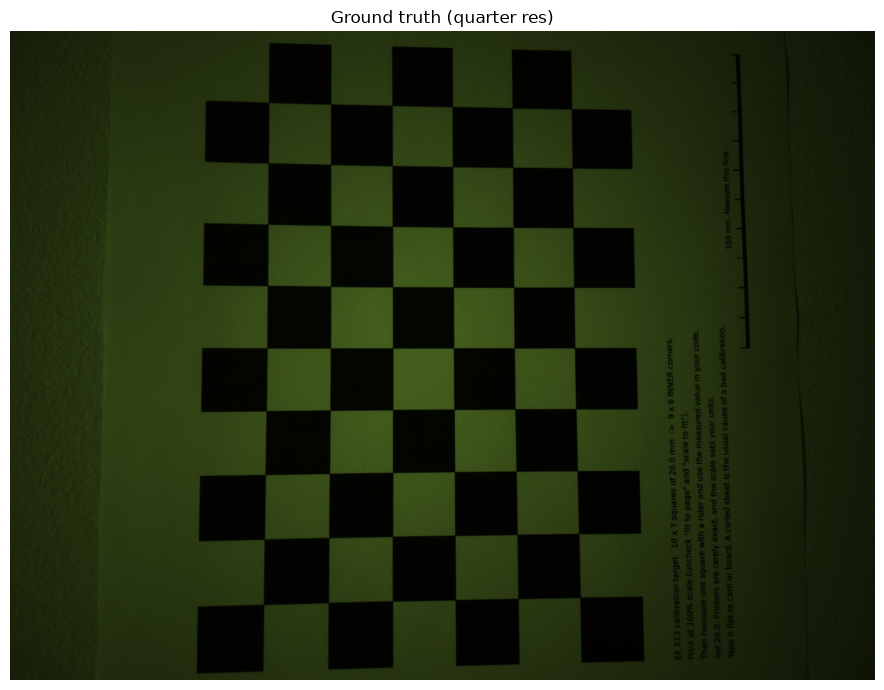

In [14]:
PATH = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards\Target13.DNG"

with rawpy.imread(PATH) as raw:
    bayer = raw.raw_image_visible.astype(np.float64)
    letters = np.array(list(raw.color_desc.decode()))   # e.g. ['R','G','B','G']
    pattern_idx = raw.raw_pattern.copy()                # 2x2 indices into color_desc
    black_per_ch = np.array(raw.black_level_per_channel, dtype=np.float64)
    white = float(raw.white_level)

pattern = letters[pattern_idx]
print("CFA pattern:", "".join(pattern.flatten()))
print("Black levels:", black_per_ch, " White level:", white)

# crop to even dimensions (so it tiles into 2x2 blocks):
H, W = bayer.shape
H2, W2 = H // 2, W // 2
bayer = bayer[: H2 * 2, : W2 * 2]

# subtract black level and normalize (per CFA site)
norm = np.empty_like(bayer)
for dy in range(2):
    for dx in range(2):
        black = black_per_ch[pattern_idx[dy, dx]]
        norm[dy::2, dx::2] = (bayer[dy::2, dx::2] - black) / (white - black)
norm = np.clip(norm, 0.0, 1.0)

#collapse down
R = np.zeros((H2, W2))
B = np.zeros((H2, W2))
G = np.zeros((H2, W2))
n_g = 0
for dy in range(2):
    for dx in range(2):
        plane = norm[dy::2, dx::2]
        c = pattern[dy, dx]
        if c == "R":
            R = plane
        elif c == "B":
            B = plane
        else:
            G = G + plane
            n_g += 1
G = G / n_g

rgb = np.dstack([R, G, B])    # linear, quarter-resolution ground truth
print("Ground truth shape:", rgb.shape, " range:", rgb.min(), "-", rgb.max())

# show the image
plt.figure(figsize=(10, 7))
plt.imshow(rgb)
plt.title("Ground truth (quarter res)")
plt.axis("off")
plt.tight_layout()
plt.show()

3. Mosaic the reference back down, so that you have a Bayer image whose correct answer you know exactly. Then confirm the round trip: re-reading the mosaic's sampled sites has to return the reference values unchanged.
Deliverable: The round-trip assertion, passing.

In [15]:
CH = {"R": 0, "G": 1, "B": 2}

# Mosaic the reference: keep one channel per pixel according to the CFA
mosaic = np.zeros(rgb.shape[:2], dtype=rgb.dtype)
for dy in range(2):
    for dx in range(2):
        mosaic[dy::2, dx::2] = rgb[dy::2, dx::2, CH[pattern[dy, dx]]]

# Round trip: re-read each sampled site and compare to the reference
for dy in range(2):
    for dx in range(2):
        c = CH[pattern[dy, dx]]
        assert np.array_equal(mosaic[dy::2, dx::2], rgb[dy::2, dx::2, c]), \
            f"Round trip failed at site ({dy},{dx})"

print("Round trip passed:", mosaic.shape, mosaic.dtype)

Round trip passed: (1512, 2016) float64


4. Explain why you couldn't have used a demosaiced version of the same capture as your reference instead.
Deliverable: Two or three sentences.

We can not use a demosaiced image as the reference because demosaicing interpolates vlaues. THis could mean that our reference would include what ever errors are present in the demosaicing step.

5. Say what the quarter resolution construction costs you.
Deliverable: One or two sentences.

Does this cost us resolution, we now have half the pixels as before.

6. Implement bilinear demosaicing yourself. Interpolate each channel from its own measured neighbors, and take care at the frame border, where a pixel has fewer neighbors than it does in the middle.
Deliverable: Your code.

In [16]:
def bilinear_demosaic(mosaic, pattern):
    H, W = mosaic.shape

    # Mask of where each channel was actually measured
    masks = np.zeros((H, W, 3), dtype=bool)
    for dy in range(2):
        for dx in range(2):
            masks[dy::2, dx::2, CH[pattern[dy, dx]]] = True

    # Bilinear kernels: R/B use the 3x3 neighborhood, G uses the 4 edge neighbors
    k_rb = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float)
    k_g  = np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=float)

    out = np.empty((H, W, 3))
    for c in range(3):
        k = k_g if c == 1 else k_rb
        m = masks[..., c].astype(float)
        num = convolve2d(mosaic * m, k, mode="same", boundary="fill")  # weighted sum of measured neighbors
        den = convolve2d(m, k, mode="same", boundary="fill")           # total weight of measured neighbors
        out[..., c] = num / den
    return out

demosaiced = bilinear_demosaic(mosaic, pattern)

7. Implement Malvar, He and Cutler yourself. Start from bilinear and add the correction term for each of the eight cases in the lecture 7 table. Write it as fixed linear filters, with no branching and no per-pixel decisions, because that's the property that makes it cheap.

In [19]:
def k5(d):                       # {(dy,dx): weight in 1/8 units} -> 5x5 kernel
    K = np.zeros((5, 5))
    for (dy, dx), w in d.items():
        K[2 + dy, 2 + dx] = w
    return K / 8.0

# ---- Bilinear part ----
BIL_G_AT_RB   = k5({(-1,0):2, (1,0):2, (0,-1):2, (0,1):2})
BIL_RB_AT_G_H = k5({(0,-1):4, (0,1):4})              # wanted colour is left/right of the G site
BIL_RB_AT_G_V = BIL_RB_AT_G_H.T                      # wanted colour is above/below
BIL_RB_AT_RB  = k5({(-1,-1):2, (-1,1):2, (1,-1):2, (1,1):2})

# ---- Correction part (gains alpha=1/2, beta=5/8, gamma=3/4 are folded in) ----
COR_G_AT_RB   = k5({(0,0):4, (0,-2):-1, (0,2):-1, (-2,0):-1, (2,0):-1})
COR_RB_AT_G_H = k5({(0,0):5, (-1,-1):-1, (-1,1):-1, (1,-1):-1, (1,1):-1,
                    (0,-2):-1, (0,2):-1, (-2,0):.5, (2,0):.5})
COR_RB_AT_G_V = COR_RB_AT_G_H.T
COR_RB_AT_RB  = k5({(0,0):6, (0,-2):-1.5, (0,2):-1.5, (-2,0):-1.5, (2,0):-1.5})

def kernel_for(pattern, dy, dx, c, with_correction=True):
    s = pattern[dy, dx]                                   # colour measured at this CFA position
    if CH[s] == c:                                        # measured: pass through
        K = np.zeros((5, 5)); K[2, 2] = 1.0
        return K
    if s != "G" and c == 1:                               # G at R / G at B   (cases 1, 2)
        b, r = BIL_G_AT_RB, COR_G_AT_RB
    elif s == "G":                                        # R or B at G       (cases 3-6)
        horiz = CH[pattern[dy, 1 - dx]] == c              # is the wanted colour left/right?
        b, r = (BIL_RB_AT_G_H, COR_RB_AT_G_H) if horiz else (BIL_RB_AT_G_V, COR_RB_AT_G_V)
    else:                                                 # R at B / B at R   (cases 7, 8)
        b, r = BIL_RB_AT_RB, COR_RB_AT_RB
    return b + r if with_correction else b

def mhc_demosaic(mosaic, pattern, with_correction=True):
    H, W = mosaic.shape
    pad = np.pad(mosaic, 2, mode="reflect")               # reflect keeps the CFA phase at the border
    out = np.empty((H, W, 3))
    for dy in range(2):
        for dx in range(2):
            for c in range(3):
                K = kernel_for(pattern, dy, dx, c, with_correction)
                f = convolve2d(pad, K, mode="valid")      # one fixed linear filter, same for every pixel
                out[dy::2, dx::2, c] = f[dy::2, dx::2]
    return np.clip(out, 0, 1)

The eight cases need only four filter patterns between them, because two of them are each other rotated by ninety degrees. Print the four you used.
Deliverable: Four arrays.

In [23]:
np.set_printoptions(precision=2, suppress=True, linewidth=120)

four = {
    "1. G at R or B locations":                    BIL_G_AT_RB   + COR_G_AT_RB,
    "2. R/B at G, wanted colour left/right":       BIL_RB_AT_G_H + COR_RB_AT_G_H,
    "3. R/B at G, wanted colour above/below":      BIL_RB_AT_G_V + COR_RB_AT_G_V,
    "4. R at B locations, or B at R locations":    BIL_RB_AT_RB  + COR_RB_AT_RB,
}

for name, K in four.items():
    print(name, "   (each entry / 8)")
    print(K * 8)
    print("sum of weights:", K.sum(), "\n")

# Check that #3 is #2 rotated by 90 degrees
print("#3 equals #2 rotated 90 degrees:", np.array_equal(four["3. R/B at G, wanted colour above/below"],
                                                         np.rot90(four["2. R/B at G, wanted colour left/right"])))

1. G at R or B locations    (each entry / 8)
[[ 0.  0. -1.  0.  0.]
 [ 0.  0.  2.  0.  0.]
 [-1.  2.  4.  2. -1.]
 [ 0.  0.  2.  0.  0.]
 [ 0.  0. -1.  0.  0.]]
sum of weights: 1.0 

2. R/B at G, wanted colour left/right    (each entry / 8)
[[ 0.   0.   0.5  0.   0. ]
 [ 0.  -1.   0.  -1.   0. ]
 [-1.   4.   5.   4.  -1. ]
 [ 0.  -1.   0.  -1.   0. ]
 [ 0.   0.   0.5  0.   0. ]]
sum of weights: 1.0 

3. R/B at G, wanted colour above/below    (each entry / 8)
[[ 0.   0.  -1.   0.   0. ]
 [ 0.  -1.   4.  -1.   0. ]
 [ 0.5  0.   5.   0.   0.5]
 [ 0.  -1.   4.  -1.   0. ]
 [ 0.   0.  -1.   0.   0. ]]
sum of weights: 1.0 

4. R at B locations, or B at R locations    (each entry / 8)
[[ 0.   0.  -1.5  0.   0. ]
 [ 0.   2.   0.   2.   0. ]
 [-1.5  0.   6.   0.  -1.5]
 [ 0.   2.   0.   2.   0. ]
 [ 0.   0.  -1.5  0.   0. ]]
sum of weights: 1.0 

#3 equals #2 rotated 90 degrees: True


9. Show what the two algorithms produced, next to the reference.
Deliverable: One figure with three panels.

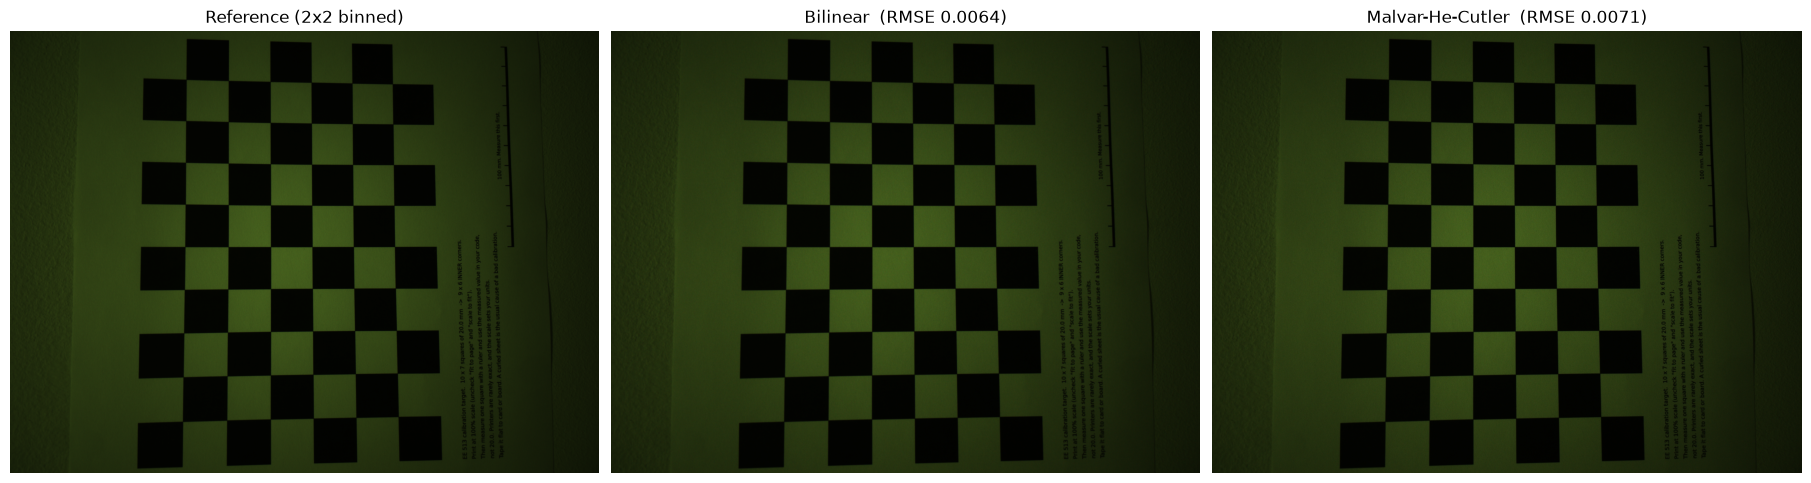

In [22]:
rmse = lambda a: np.sqrt(((a - rgb) ** 2).mean())

crop = None
sl = crop if crop else (slice(None), slice(None))

panels = [("Reference (2x2 binned)", rgb),
          (f"Bilinear  (RMSE {rmse(bil):.4f})", bil),
          (f"Malvar-He-Cutler  (RMSE {rmse(mhc):.4f})", mhc)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, (title, img) in zip(axes, panels):
    ax.imshow(img[sl])
    ax.set_title(title)
    ax.axis("off")
plt.show()

11. Check both of your implementations against the reference ones in make_figures.py from the lecture 7 slides, which are bilinear_demosaic and mhc_demosaic. That file imports psu_imaging.py, so both need to be on your path; both are on Canvas in the Slides folder. They assume an RGGB mosaic, so feed them the aligned version from item 1.
Deliverable: The largest absolute difference between your output and theirs, for each of the two methods.

In [24]:
# keep references to MY implementations (defined in earlier cells) 
my_bilinear, my_mhc = bilinear_demosaic, mhc_demosaic

# Lecture 7 implementations, renamed with a lec_ prefix 
def lec_bilinear_demosaic(bayer):
    h, w = bayer.shape
    r = np.zeros((h, w)); g = np.zeros((h, w)); b = np.zeros((h, w))
    r[0::2, 0::2] = bayer[0::2, 0::2]
    g[0::2, 1::2] = bayer[0::2, 1::2]
    g[1::2, 0::2] = bayer[1::2, 0::2]
    b[1::2, 1::2] = bayer[1::2, 1::2]

    mr = np.zeros((h, w)); mr[0::2, 0::2] = 1
    mg = np.zeros((h, w)); mg[0::2, 1::2] = 1; mg[1::2, 0::2] = 1
    mb = np.zeros((h, w)); mb[1::2, 1::2] = 1

    k_rb = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 4.0
    k_g = np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=float) / 4.0

    def norm(plane, mask, kernel):
        num = cv2.filter2D(plane, -1, kernel, borderType=cv2.BORDER_REFLECT)
        den = cv2.filter2D(mask, -1, kernel, borderType=cv2.BORDER_REFLECT)
        return num / np.maximum(den, 1e-9)

    return np.dstack([norm(r, mr, k_rb), norm(g, mg, k_g), norm(b, mb, k_rb)])


def lec_mhc_demosaic(bayer):
    h, w = bayer.shape
    out = lec_bilinear_demosaic(bayer)

    g_at_rb = np.array([
        [0, 0, -1, 0, 0],
        [0, 0, 2, 0, 0],
        [-1, 2, 4, 2, -1],
        [0, 0, 2, 0, 0],
        [0, 0, -1, 0, 0]], dtype=float) / 8.0
    rb_at_g_rrow = np.array([
        [0, 0, 0.5, 0, 0],
        [0, -1, 0, -1, 0],
        [-1, 4, 5, 4, -1],
        [0, -1, 0, -1, 0],
        [0, 0, 0.5, 0, 0]], dtype=float) / 8.0
    rb_at_g_crow = rb_at_g_rrow.T
    rb_at_br = np.array([
        [0, 0, -1.5, 0, 0],
        [0, 2, 0, 2, 0],
        [-1.5, 0, 6, 0, -1.5],
        [0, 2, 0, 2, 0],
        [0, 0, -1.5, 0, 0]], dtype=float) / 8.0

    f = lambda k: cv2.filter2D(bayer, -1, k, borderType=cv2.BORDER_REFLECT)
    g_est, rg_r, rg_c, rb_est = f(g_at_rb), f(rb_at_g_rrow), f(rb_at_g_crow), f(rb_at_br)

    out[0::2, 0::2, 1] = g_est[0::2, 0::2]
    out[1::2, 1::2, 1] = g_est[1::2, 1::2]
    out[0::2, 1::2, 0] = rg_r[0::2, 1::2]
    out[1::2, 0::2, 0] = rg_c[1::2, 0::2]
    out[0::2, 1::2, 2] = rg_c[0::2, 1::2]
    out[1::2, 0::2, 2] = rg_r[1::2, 0::2]
    out[1::2, 1::2, 0] = rb_est[1::2, 1::2]
    out[0::2, 0::2, 2] = rb_est[0::2, 0::2]

    return np.clip(out, 0, 1)


# Align the mosaic to RGGB by cropping, so the top-left pixel is R 
ry, rx = [(dy, dx) for dy in range(2) for dx in range(2) if pattern[dy, dx] == "R"][0]
m = np.ascontiguousarray(mosaic[ry:, rx:], dtype=np.float64)
m = m[: m.shape[0] // 2 * 2, : m.shape[1] // 2 * 2]
p = np.array([["R", "G"], ["G", "B"]])
assert [pattern[(ry + i) % 2, (rx + j) % 2] for i in range(2) for j in range(2)] == ["R", "G", "G", "B"]

#  Run both implementations of both methods 
results = {
    "bilinear": (my_bilinear(m, p), lec_bilinear_demosaic(m)),
    "MHC":      (my_mhc(m, p),      lec_mhc_demosaic(m)),
}

# Report:
print(f"Aligned RGGB mosaic: {m.shape}\n")
for name, (mine, theirs) in results.items():
    d = np.abs(mine - theirs)
    ring = d.copy(); ring[2:-2, 2:-2] = 0
    print(f"{name:9s} largest absolute difference: {d.max():.3e}")
    print(f"{'':9s}   interior (excl. 2-px border): {d[2:-2, 2:-2].max():.3e}")
    print(f"{'':9s}   outer 2-px border ring only : {ring.max():.3e}\n")

Aligned RGGB mosaic: (1512, 2016)

bilinear  largest absolute difference: 1.110e-16
            interior (excl. 2-px border): 1.110e-16
            outer 2-px border ring only : 5.551e-17

MHC       largest absolute difference: 1.096e-01
            interior (excl. 2-px border): 2.220e-16
            outer 2-px border ring only : 1.096e-01



11. If either difference is larger than floating point rounding, find out why before you go on. A disagreement at the border is a different problem from a disagreement in the middle, and it's worth separating the two.
Deliverable: One sentence on what caused it, or a statement that there was no disagreement.

The difference for the inerior is less than a flaoting point for both. For the exterior for the MHC method hte difference is more a floating point. I believe the difference comes from how the edge (boarder) is hnadeled. My code uses a mirroring of the pixels and the lecture code uses a reflection across the boarder. 

12. Both reference implementations leave the measured sites exactly as they found them. That's a property worth testing rather than trusting, and your own code should have it too.
Deliverable: A check that the measured sites come back unchanged, for both of your implementations.

In [25]:
CH = {"R": 0, "G": 1, "B": 2}
TOL = 4 * np.finfo(np.float64).eps        # a few rounding steps

def check_measured_sites(name, out, mosaic, pattern):
    worst = 0.0
    for dy in range(2):
        for dx in range(2):
            c = CH[pattern[dy, dx]]
            d = np.abs(out[dy::2, dx::2, c] - mosaic[dy::2, dx::2]).max()
            worst = max(worst, d)
    status = "PASS" if worst <= TOL else "FAIL"
    print(f"{name:14s} largest change at measured sites: {worst:.2e}   {status}"
          f"{'  (bit-exact)' if worst == 0 else ''}")
    assert worst <= TOL, f"{name}: measured sites were altered"

check_measured_sites("my bilinear",  my_bilinear(m, p),           m, p)
check_measured_sites("my MHC",       my_mhc(m, p),                m, p)
check_measured_sites("lec bilinear", lec_bilinear_demosaic(m),    m, p)
check_measured_sites("lec MHC",      lec_mhc_demosaic(m),         m, p)

my bilinear    largest change at measured sites: 0.00e+00   PASS  (bit-exact)
my MHC         largest change at measured sites: 0.00e+00   PASS  (bit-exact)
lec bilinear   largest change at measured sites: 2.78e-17   PASS
lec MHC        largest change at measured sites: 2.78e-17   PASS


13. Report PSNR against your reference for both methods, over the whole frame, and then again over the middle of the frame only, with a margin of a few pixels excluded on every side. State the peak value you used in the caption.
Deliverable: A small table of four PSNR values.

In [27]:
PEAK   = 1.0      # the data is normalized to [0, 1] (black level subtracted, divided by white - black)
MARGIN = 4        # pixels excluded on every side for the "middle of the frame" numbers

# Reference cropped the same way as the aligned mosaic m
ref = rgb[ry:, rx:][: m.shape[0], : m.shape[1]]
assert ref.shape[:2] == m.shape

def psnr(a, b, peak=PEAK):
    mse = np.mean((a - b) ** 2)          # averaged over all pixels and all three channels
    return np.inf if mse == 0 else 10 * np.log10(peak ** 2 / mse)

inner = (slice(MARGIN, -MARGIN), slice(MARGIN, -MARGIN))
outputs = {"Bilinear": my_bilinear(m, p), "Malvar-He-Cutler": my_mhc(m, p)}

rows = [(name, psnr(out, ref), psnr(out[inner], ref[inner])) for name, out in outputs.items()]

print(f"{'Method':<18}{'Whole frame (dB)':>18}{f'Center, {MARGIN}-px margin (dB)':>30}")
for name, full, mid in rows:
    print(f"{name:<18}{full:>18.2f}{mid:>30.2f}")



Method              Whole frame (dB)      Center, 4-px margin (dB)
Bilinear                       43.92                         43.91
Malvar-He-Cutler               42.93                         42.92


One was used as the peak value (so the data is normalized to [0,1]). The margin was set as 4 pixels to be twice the 2 pixels used by the MHC filters.

14. Say what the border exclusion changed, and why.
Deliverable: One or two sentences.

The boarder exclusion actually decreased PSNR, I would have thought it would have increased it as there would have been errors from the handling of the boarder conditions. 

15. Your reference came out of a single raw frame, so it carries the sensor's noise in every pixel, and the two algorithms don't treat noise the same way. Box-average your reference down by another factor of two, which halves the noise standard deviation, mosaic that down, and run both methods again.
Deliverable: Two more PSNR values, for bilinear and for Malvar, He and Cutler on the quieter reference.

In [28]:
CH = {"R": 0, "G": 1, "B": 2}

def make_mosaic(img, pattern):
    out = np.zeros(img.shape[:2])
    for dy in range(2):
        for dx in range(2):
            out[dy::2, dx::2] = img[dy::2, dx::2, CH[pattern[dy, dx]]]
    return out

# ---- Box-average the reference down by another factor of 2 ----
h, w = ref.shape[0] // 2 * 2, ref.shape[1] // 2 * 2
ref_q = ref[:h, :w].reshape(h // 2, 2, w // 2, 2, 3).mean(axis=(1, 3))   # mean of each 2x2 block
hq, wq = ref_q.shape[0] // 2 * 2, ref_q.shape[1] // 2 * 2
ref_q = ref_q[:hq, :wq]                                                   # even size so it tiles into the CFA

# ---- Mosaic it (RGGB, the same aligned pattern p) and run both methods ----
m_q = make_mosaic(ref_q, p)
inner = (slice(MARGIN, -MARGIN), slice(MARGIN, -MARGIN))

print(f"Quieter reference: {ref_q.shape}, peak {PEAK:g}, center excludes a {MARGIN}-px margin\n")
print(f"{'Method':<18}{'Whole frame (dB)':>18}{'Center (dB)':>14}{'  | original ref, whole (dB)':>30}")
for name, f in [("Bilinear", my_bilinear), ("Malvar-He-Cutler", my_mhc)]:
    out_q = f(m_q, p)
    out_0 = f(make_mosaic(ref, p), p)
    print(f"{name:<18}{psnr(out_q, ref_q):>18.2f}{psnr(out_q[inner], ref_q[inner]):>14.2f}"
          f"{psnr(out_0, ref):>30.2f}")

Quieter reference: (756, 1008, 3), peak 1, center excludes a 4-px margin

Method              Whole frame (dB)   Center (dB)    | original ref, whole (dB)
Bilinear                       44.33         44.28                         43.92
Malvar-He-Cutler               45.20         45.15                         42.93


16. Compare the gap between the two methods before and after, and explain what changed. Adding up the squares of the weights in your filters will tell you most of it.
Deliverable: Two or three sentences.

The MHC is better than the Bilinear when using the lower noise image, I think this may mean that the MHC is more suceptable to noise. looking at the sum of the squared weights, they are much larger in the MHC method than for bilinear method. So this must be doing a larger amplification (gain?) of the noise than the biliear does, therefore in the more noisy example the passing through more noise some what cancels the benifits of the MHC compared to the bilinear

17. Now look at the images instead of the numbers. Find a near-vertical or near-horizontal edge and show a magnified crop of it from both methods and from the reference, along with the absolute error for each.
Deliverable: One figure of magnified crops with their error maps.

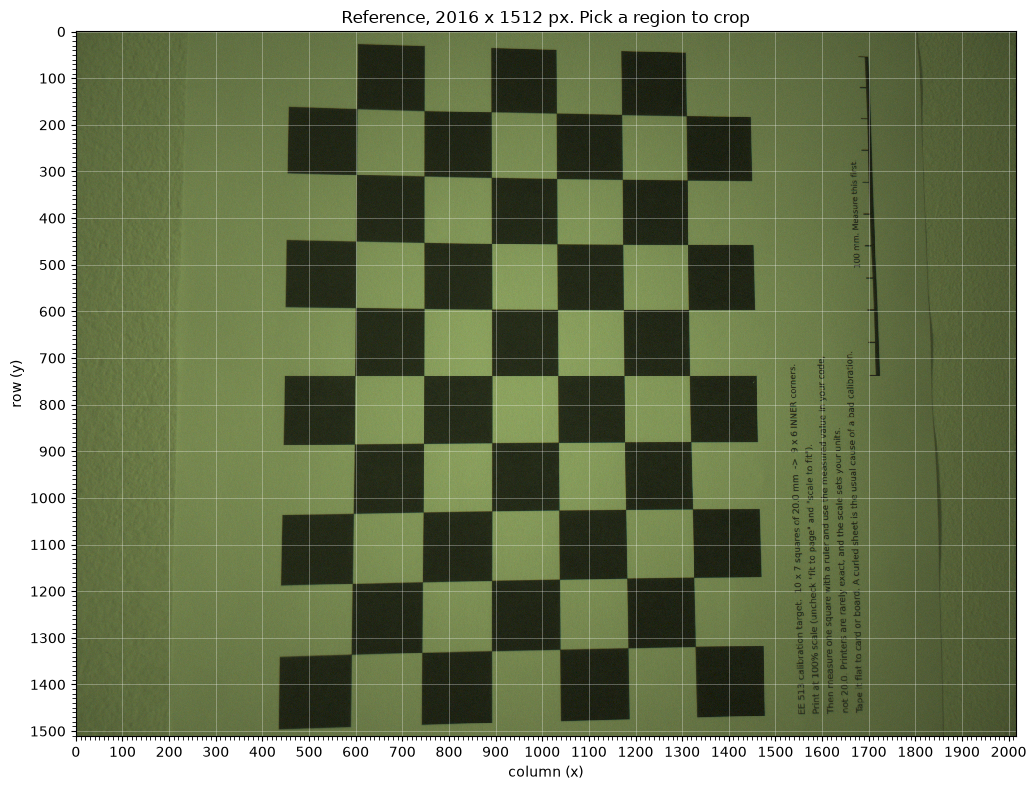

In [30]:
# start with vieualizing the capture and determine what area I want ot zoom in on:
view = np.clip(ref, 0, 1) ** (1 / 2.2)        # gamma for display only

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(view, interpolation="nearest")
ax.set_xlabel("column (x)")
ax.set_ylabel("row (y)")
ax.set_title(f"Reference, {ref.shape[1]} x {ref.shape[0]} px. Pick a region to crop")

# Finer tick spacing and a light grid make it easier to read off coordinates
ax.set_xticks(np.arange(0, ref.shape[1], 100))
ax.set_yticks(np.arange(0, ref.shape[0], 100))
ax.set_xticks(np.arange(0, ref.shape[1], 10), minor=True)
ax.set_yticks(np.arange(0, ref.shape[0], 10), minor=True)
ax.grid(which="major", color="w", alpha=0.35, linewidth=0.6)
ax.tick_params(which="minor", length=3)

plt.tight_layout()
plt.show()

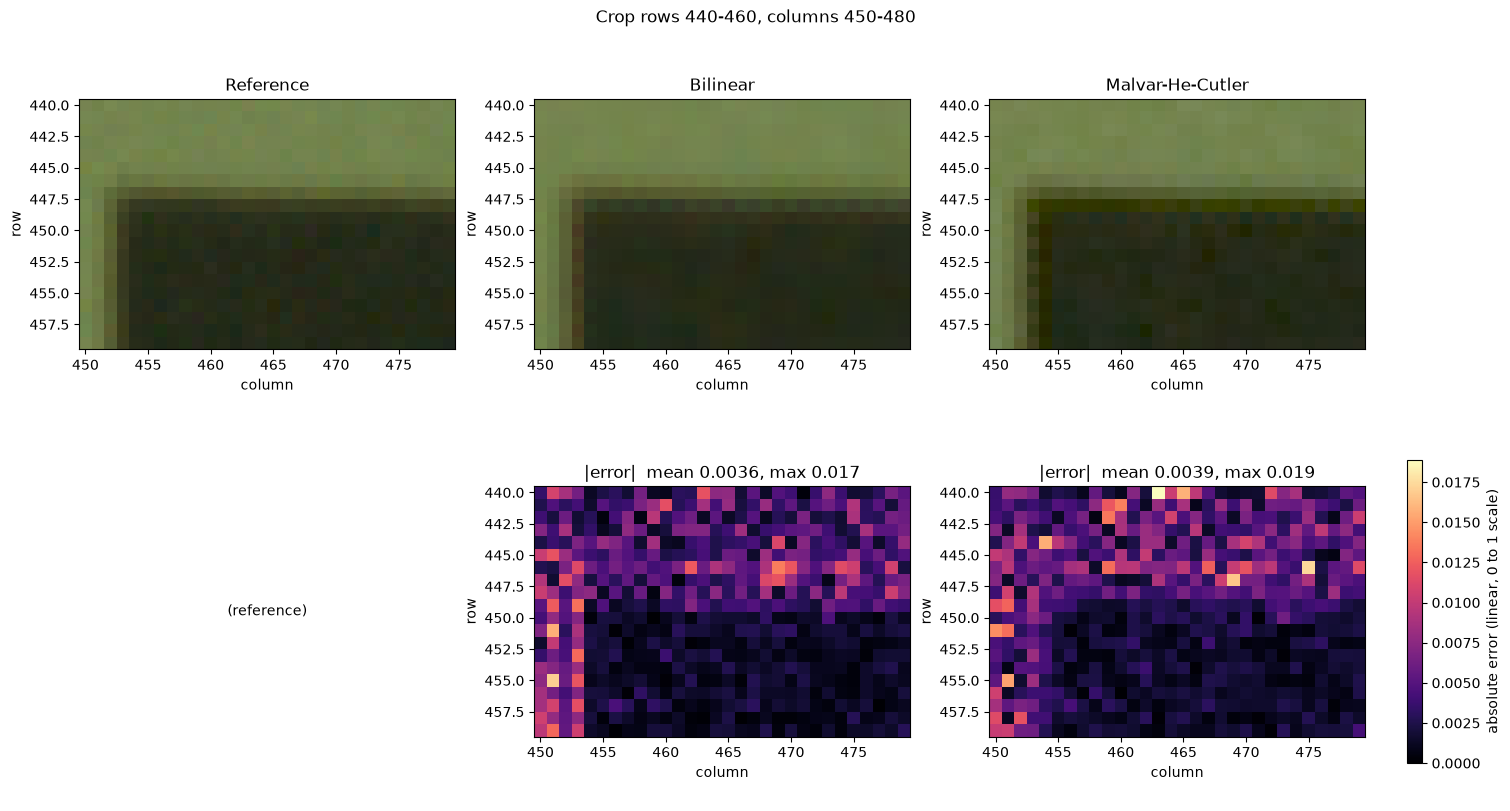

In [38]:
r0, r1 = 440, 460      # rows
c0, c1 = 450, 480      # columns
sl = (slice(r0, r1), slice(c0, c1))

bil = my_bilinear(m, p)
mhc = my_mhc(m, p)
assert ref.shape == bil.shape == mhc.shape, "ref and outputs must have the same shape"

gamma = lambda a: np.clip(a, 0, 1) ** (1 / 2.2)          # display only
err = lambda a: np.abs(a - ref).mean(axis=2)             # absolute error, averaged over R, G, B

images = [("Reference", ref), ("Bilinear", bil), ("Malvar-He-Cutler", mhc)]
errors = [None, err(bil), err(mhc)]
emax = max(e[sl].max() for e in errors if e is not None)  # one shared color scale for both error maps

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
extent = (c0 - 0.5, c1 - 0.5, r1 - 0.5, r0 - 0.5)         # keeps full-image pixel coordinates on the axes

for j, (title, img) in enumerate(images):
    axes[0, j].imshow(gamma(img[sl]), interpolation="nearest", extent=extent)
    axes[0, j].set_title(title)

    if errors[j] is None:
        axes[1, j].axis("off")
        axes[1, j].text(0.5, 0.5, "(reference)", ha="center", va="center", transform=axes[1, j].transAxes)
    else:
        e = errors[j][sl]
        im = axes[1, j].imshow(e, cmap="magma", vmin=0, vmax=emax, interpolation="nearest", extent=extent)
        axes[1, j].set_title(f"|error|  mean {e.mean():.4f}, max {e.max():.3f}")

for ax in axes.ravel():
    ax.set_xlabel("column"); ax.set_ylabel("row")

fig.colorbar(im, ax=axes[1, 1:], shrink=0.8, label="absolute error (linear, 0 to 1 scale)")
fig.suptitle(f"Crop rows {r0}-{r1}, columns {c0}-{c1}")
plt.show()

18. Find somewhere the gradient correction doesn't help, or makes things worse, and show it the same way. There's always somewhere.
Deliverable: One figure of magnified crops with their error maps.

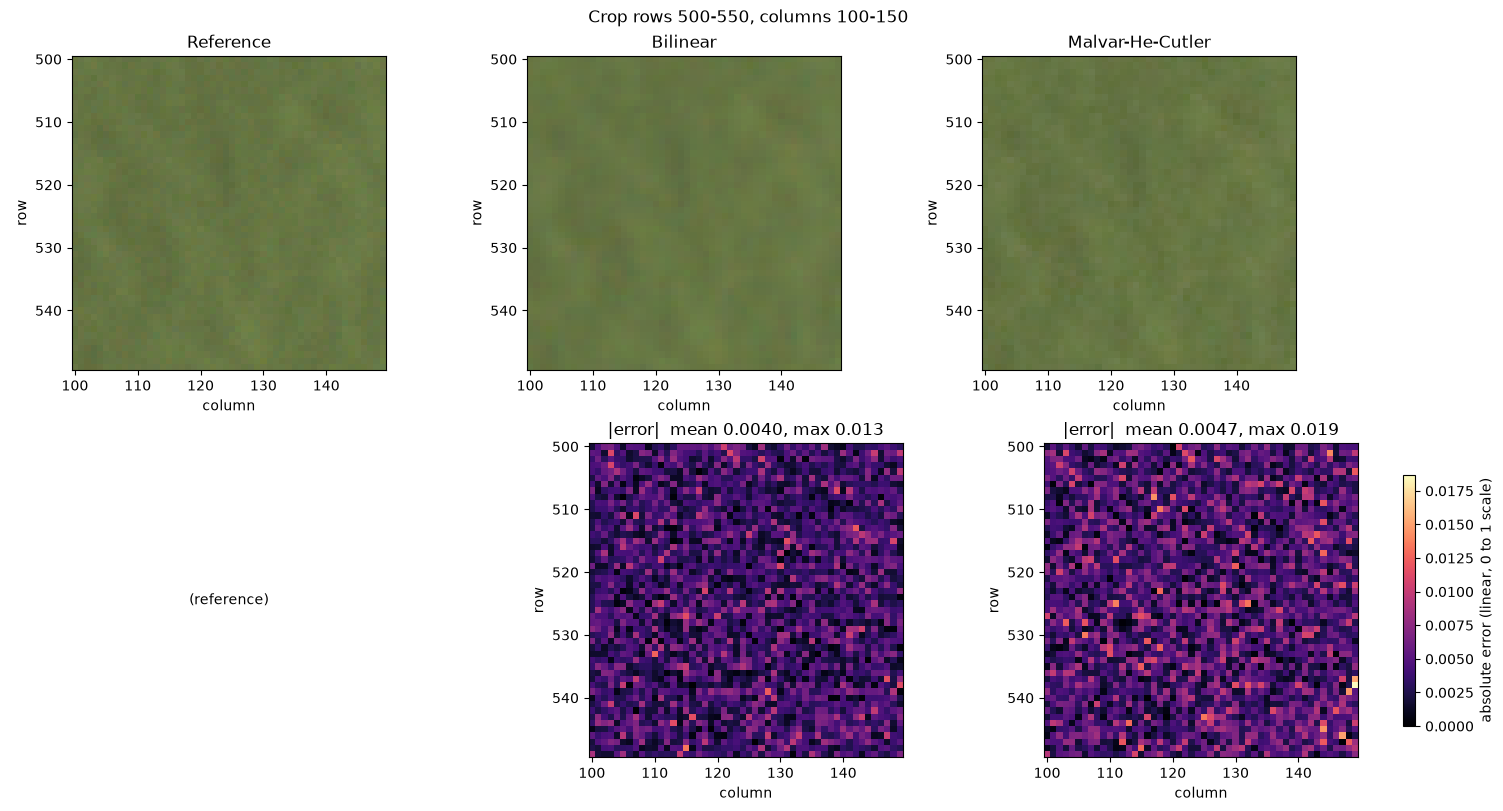

In [34]:
r0, r1 = 500, 550      # rows
c0, c1 = 100, 150      # columns
sl = (slice(r0, r1), slice(c0, c1))

bil = my_bilinear(m, p)
mhc = my_mhc(m, p)
assert ref.shape == bil.shape == mhc.shape, "ref and outputs must have the same shape"

gamma = lambda a: np.clip(a, 0, 1) ** (1 / 2.2)          # display only
err = lambda a: np.abs(a - ref).mean(axis=2)             # absolute error, averaged over R, G, B

images = [("Reference", ref), ("Bilinear", bil), ("Malvar-He-Cutler", mhc)]
errors = [None, err(bil), err(mhc)]
emax = max(e[sl].max() for e in errors if e is not None)  # one shared color scale for both error maps

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
extent = (c0 - 0.5, c1 - 0.5, r1 - 0.5, r0 - 0.5)         # keeps full-image pixel coordinates on the axes

for j, (title, img) in enumerate(images):
    axes[0, j].imshow(gamma(img[sl]), interpolation="nearest", extent=extent)
    axes[0, j].set_title(title)

    if errors[j] is None:
        axes[1, j].axis("off")
        axes[1, j].text(0.5, 0.5, "(reference)", ha="center", va="center", transform=axes[1, j].transAxes)
    else:
        e = errors[j][sl]
        im = axes[1, j].imshow(e, cmap="magma", vmin=0, vmax=emax, interpolation="nearest", extent=extent)
        axes[1, j].set_title(f"|error|  mean {e.mean():.4f}, max {e.max():.3f}")

for ax in axes.ravel():
    ax.set_xlabel("column"); ax.set_ylabel("row")

fig.colorbar(im, ax=axes[1, 1:], shrink=0.8, label="absolute error (linear, 0 to 1 scale)")
fig.suptitle(f"Crop rows {r0}-{r1}, columns {c0}-{c1}")
plt.show()

19. Name the artifacts you found in the last two figures, and say what kind of image content produced each one.
Deliverable: Two or three sentences

It seems like the MHC method did worse on a flat noisey section, as we found earlier the MHC does worse for passing noise. I think this makes sense if you think about how the idea is that fine detail comes from brightness share dbetween channels, but if there isnt ine detail inthe region than what we pick up is brighness changes from noise. We can see though that the bilinear did worse on the image of black square along the edge of the square, this makes sense as it is averaging near by values of the same channel but if we're slightly on the white side the interpolated value will be pulled by the white area and if we're slightly to the black side the interpolated value will be pulled by the black values, so we end up with a zippering effect, I think we can see the MHC has less of this zippering effect.

20. What did you learn from this assignment?
Deliverable: A brief written response.

Thinking about why different methods to demosaic may fail. Even though we may think of the MHC method as being more the sophisticated method there are still situations and image parts where it is significantly worse. Therefor it is important to know the limitations of a method and where it performs well and poorly instead of just blindly applying because we think it will work better.

21. What questions do you have for me?
Deliverable: A brief written response.

Maybe this is incorrect, but to make the MHC work better could we first smooth the image more to decrease the effects of noise, I guess than we trading something when it comes to fine details by doing that smoothing?

22. Use of AI: I used ai to help with coding python in this assignment, I primarily used claud code. I also used to help study how the MHC and bilinear interpolation methods work and why they would work better in some situations vs others. This is not nessacarily about how to check AI code out puts, but i think if we are using AI to produce parts of code than it is extra important to be learning the concepts and AI can also be a good starting point in clariying and checking your understanding of those topic. I do wonder what we do if we are using AI to help study but it gets something wrong, I guess that highlights why published text books and literature still have value because they have been reviewed to a higher standard. 